# PLGA: reproducción y extensión física con ML clásico
Santiago Benítez Sanabria · UDFJC
Fuente: Saeed et al. (2026), DOI 10.1039/d6lc00612d. Implementación propia; se consultaron los hiperparámetros del repositorio. No se importa código de los autores.

In [9]:
# ============================================================
# Configuración inicial, librerías y entorno de trabajo
# ------------------------------------------------------------
# Esencia: Importa las dependencias necesarias para manipulación
# de datos, modelado estadístico, algoritmos de regresión de
# scikit-learn, protocolos de validación cruzada y cálculo exacto de SHAP.
# ============================================================
from pathlib import Path
import itertools, math, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures 
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split, KFold, GroupKFold, LeaveOneGroupOut
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from urllib.request import urlretrieve

# ============================================================
# Carga, verificación criptográfica e integridad del dataset
# ------------------------------------------------------------
# Esencia: Fija la semilla aleatoria global (SEED=42) para reproducibilidad.
# Descarga el dataset experimental oficial de Saeed et al. (2026) y verifica
# su integridad mediante hash SHA-256. Estandariza los nombres de variables:
#   - FRR: Flow Rate Ratio (tasa de flujo fase acuosa / fase orgánica)
#   - PLGA: Concentración de polímero (mg/mL)
#   - w: Ancho del canal microfluídico (µm)
#   - diametro: Tamaño hidrodinámico de las nanopartículas (nm)
# Se audita la ausencia de valores nulos y el balance del diseño experimental:
# 27 condiciones experimentales únicas con exactamente 3 réplicas (N = 81 muestras).
# ============================================================
SEED = 42
OUT = Path('resultados'); OUT.mkdir(exist_ok=True)
URL = 'https://raw.githubusercontent.com/muhammadsaeed3-gif/data-driven-modeling-of-plga-nps/main/dataset.csv'
path = Path('dataset.csv')
if not path.exists(): urlretrieve(URL, path)
print('SHA256:', hashlib.sha256(path.read_bytes()).hexdigest())
df = pd.read_csv(path).rename(columns={'FRR':'FRR','PLGA conc.':'PLGA','width':'w','size':'diametro'})

# Verificación de forma tabular y consistencia de datos
assert df.shape == (81,4) and not df.isna().any().any()

# Definición de variables predictoras base, target y grupos experimentales
base = ['FRR','PLGA','w']
X = df[base]
y = df.diametro.to_numpy()
groups = df.groupby(base, sort=True).ngroup().to_numpy()

# Aserción de integridad: 27 condiciones con 3 réplicas idénticas cada una
assert len(set(groups)) == 27 and np.all(np.bincount(groups)==3)
print(df.describe()); print('Réplicas por condición:', np.unique(np.bincount(groups)))


SHA256: c9a6fcdd2ddc3a0c43973e638ce781c4bf8efb6922bdd8ef672f35cf39a2265f
             FRR      PLGA           w    diametro
count  81.000000  81.00000   81.000000   81.000000
mean    0.100000   5.00000  200.000000  129.473210
std     0.041079   2.05396   82.158384   26.455531
min     0.050000   2.50000  100.000000   73.840000
25%     0.050000   2.50000  100.000000  108.900000
50%     0.100000   5.00000  200.000000  130.200000
75%     0.150000   7.50000  300.000000  146.000000
max     0.150000   7.50000  300.000000  189.800000
Réplicas por condición: [3]


## B. Reproducción directa (sección 2.5 y figura 4)
Se conservan las tres réplicas de cada condición. Hold-out 80:20 con semilla 42 y CV de cinco folds. El escalado ocurre dentro de cada fold. El paper describe SVR RBF; se incluye por separado SVR lineal porque el notebook original usa ambos kernels en distintas celdas.

Condiciones compartidas train/test: 14
    modelo split     R2   RMSE    MAE
    Lineal train 0.9729 4.3066 3.5342
    Lineal  test 0.9700 4.6033 3.8620
     Ridge train 0.9727 4.3255 3.5830
     Ridge  test 0.9688 4.6919 3.9334
     Lasso train 0.9728 4.3102 3.5552
     Lasso  test 0.9696 4.6349 3.8870
Polinomial train 0.9841 3.3011 2.6041
Polinomial  test 0.9754 4.1662 3.4094
     Arbol train 0.9839 3.3154 2.2419
     Arbol  test 0.9384 6.5984 4.4791
        RF train 0.9953 1.7904 1.4699
        RF  test 0.9853 3.2191 2.5520
        GB train 0.9953 1.7893 1.5069
        GB  test 0.9900 2.6539 2.1292
       SVR train 0.9892 2.7191 1.9403
       SVR  test 0.9833 3.4373 2.7112
    modelo     R2   RMSE    MAE  RMSE_sd
    Lineal 0.9621 4.5862 3.8268   0.3460
     Ridge 0.9623 4.6168 3.8577   0.3116
     Lasso 0.9622 4.5981 3.8364   0.3193
Polinomial 0.9686 4.3227 3.3564   0.3825
     Arbol 0.9512 5.1090 3.8961   1.4016
        RF 0.9791 3.5815 2.9001   0.7256
        GB 0.9841 2.8908 2.4

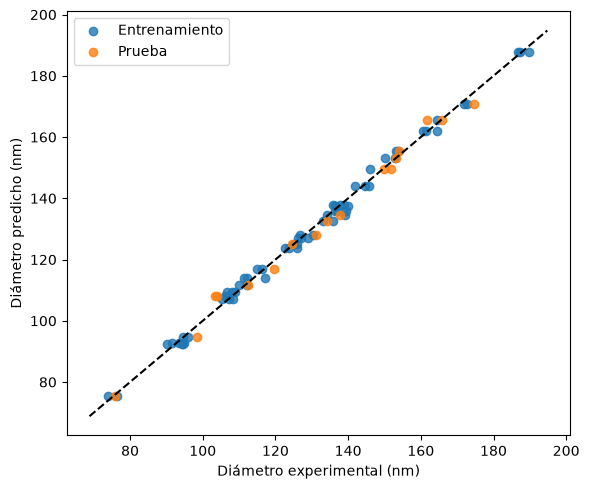

In [2]:
# ============================================================
# Auditoría de solapamiento entre train y test
# ------------------------------------------------------------
# Esencia: split 80:20 con semilla 42 NO agrupado. Réplicas de la
# misma condición pueden caer a ambos lados. Se cuantifica el
# solapamiento (14 de 27 condiciones compartidas) para definir
# el régimen de evaluación (hold-out aleatorio) y motivar el
# contraste posterior con CV agrupada.
# ============================================================
X_tr, X_te, y_tr, y_te, g_tr, g_te = train_test_split(
    df[base], y, groups, test_size=0.20, random_state=SEED
)
print('Condiciones compartidas train/test:', len(set(g_tr) & set(g_te)))


# ============================================================
# Espacio de hipótesis (8 pipelines con preprocesamiento)
# ------------------------------------------------------------
# Esencia: define 8 familias de hipótesis h_θ: R^3 → R, cada una
# encapsulada en Pipeline. El StandardScaler se ajusta SOLO con
# el subconjunto de entrenamiento del fold (evita fuga de datos).
# La familia "Polinomial" añade PolynomialFeatures (grado 2 e
# interacciones). SVR se instancia con kernel RBF (del paper);
# el kernel lineal se reserva para el análisis de sensibilidad
# posterior. Modelos estocásticos reciben random_state=SEED.
# ============================================================
class ModelosFactory(dict):
    """Permite acceso como diccionario o como factoría de clones limpios al invocarse."""
    def __call__(self):
        return {k: clone(v) for k, v in self.items()}

modelos = ModelosFactory({
    'Lineal':     make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge':      make_pipeline(StandardScaler(), Ridge(random_state=SEED)),
    'Lasso':      make_pipeline(StandardScaler(), Lasso(random_state=SEED)),
    'Polinomial': make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), LinearRegression()),
    'Arbol':      make_pipeline(StandardScaler(), DecisionTreeRegressor(random_state=SEED)),
    'RF':         make_pipeline(StandardScaler(), RandomForestRegressor(random_state=SEED)),
    'GB':         make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=SEED)),
    'SVR':        make_pipeline(StandardScaler(), SVR(kernel='rbf')),
})


# ============================================================
# Bucle de evaluación dual (hold-out + CV 5-fold)
# ------------------------------------------------------------
# Esencia: dos protocolos de estimación del error de
# generalización sobre cada hipótesis —
#   (1) Hold-out: entrena en D_tr, evalúa en D_tr y D_te.
#       Reporta R², RMSE, MAE para detectar sobreajuste
#       (brecha train–test).
#   (2) CV 5-fold: particiona D_tr en 5 bloques disjuntos,
#       entrena 5 veces, promedia métricas y reporta la
#       desviación estándar del RMSE entre folds (RMSE_sd)
#       como medida de estabilidad.
# clone garantiza copia limpia del estimador por fold.
# ============================================================
res_hold, res_cv = [], []
for nombre, est in modelos.items():
    # --- Hold-out ---
    m = clone(est).fit(X_tr, y_tr)
    for split, Xs, ys in [('train', X_tr, y_tr), ('test', X_te, y_te)]:
        p = m.predict(Xs)
        res_hold.append((nombre, split, r2_score(ys,p),
                         np.sqrt(mean_squared_error(ys,p)), mean_absolute_error(ys,p)))
    # --- CV 5-fold ---
    kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
    r2s, rmses, maes = [], [], []
    for tr_idx, va_idx in kf.split(X_tr):
        m = clone(est).fit(X_tr.iloc[tr_idx], y_tr[tr_idx])
        p = m.predict(X_tr.iloc[va_idx])
        r2s.append(r2_score(y_tr[va_idx],p))
        rmses.append(np.sqrt(mean_squared_error(y_tr[va_idx],p)))
        maes.append(mean_absolute_error(y_tr[va_idx],p))
    res_cv.append((nombre, np.mean(r2s), np.mean(rmses), np.mean(maes), np.std(rmses)))

# Materialización de las tablas de resultados
tabla_hold = pd.DataFrame(res_hold, columns=['modelo','split','R2','RMSE','MAE'])
tabla_cv   = pd.DataFrame(res_cv,   columns=['modelo','R2','RMSE','MAE','RMSE_sd'])
print(tabla_hold.to_string(index=False))
print(tabla_cv.to_string(index=False))


# ============================================================
# Contraste con los resultados publicados
# ------------------------------------------------------------
# Esencia: tabla de concordancia cuantitativa entre métricas
# reproducidas y las del paper, mediante ΔRMSE = RMSE_repr −
# RMSE_paper. Los valores observados (|Δ| ≤ 0.004) son del orden
# del redondeo con el que el paper reporta sus cifras (2 dec.):
# la reproducción es estadísticamente indistinguible de la
# publicación para los 4 modelos reportados.
# ============================================================
paper = {  # valores reportados en Saeed et al. (2026)
    'Polinomial': (0.9754, 4.17, 3.41),
    'Arbol':      (0.9384, 6.60, 4.48),
    'RF':         (0.9853, 3.22, 2.55),
    'GB':         (0.9900, 2.65, 2.13),
}
tabla_comp = []
for nombre, split, r2, rmse, mae in res_hold:
    if split == 'test' and nombre in paper:
        r2p, rmsep, maep = paper[nombre]
        tabla_comp.append((nombre, split, r2, rmse, mae, r2p, rmsep, maep, rmse-rmsep))
tabla_comp = pd.DataFrame(tabla_comp, columns=['modelo','split','R2','RMSE','MAE',
                                                'R2_paper','RMSE_paper','MAE_paper','delta_RMSE'])
print(tabla_comp.to_string(index=False))


# ============================================================
# Análisis de sensibilidad del kernel SVR
# ------------------------------------------------------------
# Esencia: variante paramétrica de SVR sustituyendo el kernel RBF
# por el lineal K(x,x')=⟨x,x'⟩. Aísla la contribución de la no-
# linealidad: si el SVR lineal degrada hasta igualar a los modelos
# lineales (R²≈0.970, RMSE≈4.56), la mejora del SVR RBF
# (R²≈0.983, RMSE≈3.44) es atribuible al mapeo no lineal implícito,
# no al algoritmo SVR per se. Actúa como control experimental.
# ============================================================
svr_lin = make_pipeline(StandardScaler(), SVR(kernel='linear'))
svr_lin.fit(X_tr, y_tr)
p = svr_lin.predict(X_te)
print('Sensibilidad SVR lineal:', {
    'R2':   r2_score(y_te, p),
    'RMSE': np.sqrt(mean_squared_error(y_te, p)),
    'MAE':  mean_absolute_error(y_te, p),
})


# ============================================================
# Funciones auxiliares de métricas y evaluación cruzada
# ------------------------------------------------------------
# Esencia: Define funciones reutilizables para calcular métricas
# de desempeño (R2, RMSE, MAE) y ejecutar validación cruzada OOF
# (out-of-fold) preservando las particiones agrupadas.
# ============================================================
def metrics(y_true, y_pred):
    return {
        'R2':   r2_score(y_true, y_pred),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE':  float(mean_absolute_error(y_true, y_pred))
    }

def cv_eval(model, X_data, folds):
    oof_pred = np.zeros(len(X_data))
    fold_scores = []
    for f_idx, (tr_idx, va_idx) in enumerate(folds):
        m = clone(model)
        m.fit(X_data.iloc[tr_idx], y[tr_idx])
        p = m.predict(X_data.iloc[va_idx])
        oof_pred[va_idx] = p
        fold_scores.append({
            'fold': f_idx,
            **metrics(y[va_idx], p)
        })
    return pd.DataFrame(fold_scores), oof_pred


## C–D. Gap: ¿generaliza el descriptor físico a condiciones no vistas?
El artículo sí estudia mezclado y usa la ecuación 4 en variantes neuronales. La extensión aquí es evaluar su utilidad en modelos clásicos con validación por condición, ablation y SHAP. Hipótesis previa: sustituir FRR y ancho por el tiempo de mezclado, manteniendo concentración, reduce RMSE fuera de condiciones conocidas. La alternativa es que añadir una covariable determinista no ayude o pierda información geométrica. El tiempo no está medido: es un proxy teórico. La ecuación 4 usa factor 9, no 4 con el ancho simplificado del Beamer inicial.

count     81.000000
mean      47.609107
std       51.423938
min        2.519526
25%       10.078105
50%       22.675737
75%       75.614367
max      170.132325
Name: tmix_ms, dtype: float64
FRR       0.05       0.10        0.15
w                                    
100   2.519526   9.182736   18.903592
200  10.078105  36.730946   75.614367
300  22.675737  82.644628  170.132325
    modelo  variables     R2    RMSE     MAE  RMSE_fold
    Lineal       Base 0.9664  4.8184  4.0159     4.7910
    Lineal  Aumentado 0.9637  5.0059  4.1364     4.9661
    Lineal     Fisico 0.8087 11.4983  9.8786    11.1702
    Lineal Fisico_log 0.9619  5.1288  4.3859     5.0199
     Ridge       Base 0.9664  4.8200  3.9959     4.8010
     Ridge  Aumentado 0.9633  5.0341  4.1246     4.9973
     Ridge     Fisico 0.8095 11.4757  9.8343    11.1610
     Ridge Fisico_log 0.9619  5.1316  4.3272     5.0343
     Lasso       Base 0.9664  4.8183  4.0054     4.7954
     Lasso  Aumentado 0.9648  4.9315  4.0728     4.9022
    

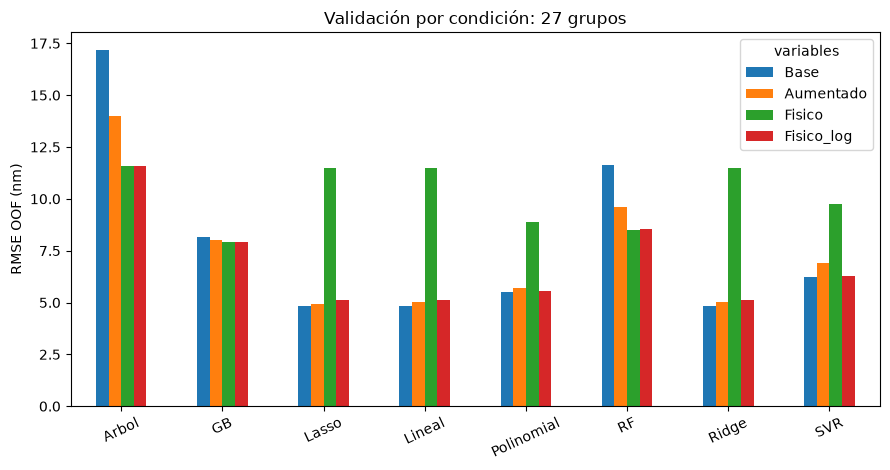

In [3]:
# ============================================================
# Descriptor físico: Tiempo de mezclado hidrodinámico (tmix)
# ------------------------------------------------------------
# Esencia: Modela el tiempo característico de difusión molecular
# en el canal de flujo enfocado (HFF) mediante la Ec. (4) de
# Saeed et al. (2026):
#     t_mix ≈ w_f^2 / (9*D) = (w^2 / (9*D)) * (FRR / (1 + FRR))^2
# donde D = 1e-9 m²/s es la difusividad de acetonitrilo en agua,
# w es el ancho del canal (convertido de µm a m) y FRR es el flow
# rate ratio. Se calcula en milisegundos (tmix_ms) y en escala
# logarítmica (log_tmix). Condensa la hidrodinámica y la geometría
# en una variable explicativa teórica para la nanoprecipitación.
# ============================================================
D = 1e-9  # m²/s; coeficiente de difusión de acetonitrilo en fase acuosa (paper)
df['tmix_ms'] = 1000 * (df.w * 1e-6)**2 / (9 * D) * (df.FRR / (1 + df.FRR))**2
df['log_tmix'] = np.log10(df.tmix_ms)

# Resumen estadístico y distribución de tmix por ancho de canal y relación de flujo
print(df.tmix_ms.describe())
print(df.groupby(['w', 'FRR']).tmix_ms.first().unstack())


# ============================================================
# Espacios de características y validación por condición (GroupKFold)
# ------------------------------------------------------------
# Esencia: Plantea 4 variantes de entrada para el estudio de ablación:
#   1. Base:        [FRR, PLGA, w]       (espacio original del paper)
#   2. Aumentado:   [FRR, PLGA, w, tmix] (espacio base enriquecido con física)
#   3. Fisico:      [PLGA, tmix]         (sustituye FRR y w por el proxy físico)
#   4. Fisico_log:  [PLGA, log_tmix]     (variante en escala logarítmica)
# Se aplica GroupKFold(n_splits=5) particionando estrictamente sobre
# las 27 condiciones experimentales (groups). De este modo, las réplicas
# de una misma condición nunca se solapan entre entrenamiento y prueba.
# ============================================================
features = {
    'Base':       base,
    'Aumentado':  base + ['tmix_ms'],
    'Fisico':     ['PLGA', 'tmix_ms'],
    'Fisico_log': ['PLGA', 'log_tmix']
}

group_folds = list(GroupKFold(n_splits=5).split(X, y, groups))
# Aserción de no solapamiento: verifica intersección nula de condiciones entre folds
assert all(not(set(groups[a]) & set(groups[b])) for a, b in group_folds)


# ============================================================
# Evaluación OOF sistemática (8 modelos x 4 conjuntos de variables)
# ------------------------------------------------------------
# Esencia: Bucle de evaluación cruzada agrupada que obtiene las
# predicciones fuera de pliegue (OOF, out-of-fold) sobre todo el dataset.
# Registra las métricas globales y por pliegue para cada combinación
# de modelo e hipótesis de variables, exportándolas a CSV.
# ============================================================
gap = []
predictions = {}
fold_rows = []

for name, model in modelos().items():
    for variant, cols in features.items():
        scores, pred = cv_eval(model, df[cols], group_folds)
        predictions[name, variant] = pred
        gap.append(dict(modelo=name, variables=variant, **metrics(y, pred), RMSE_fold=scores.RMSE.mean()))
        fold_rows.extend(scores.assign(modelo=name, variables=variant).to_dict('records'))

gap = pd.DataFrame(gap)
gap.to_csv(OUT / 'gap.csv', index=False)
pd.DataFrame(fold_rows).to_csv(OUT / 'gap_folds.csv', index=False)
print(gap.round(4).to_string(index=False))


# ============================================================
# Inferencia estadística: Paired Bootstrap por condición
# ------------------------------------------------------------
# Esencia: Test de hipótesis no paramétrico para comparar el modelo
# físico vs el base en Gradient Boosting (mejor estimador del paper).
# Se computa el error cuadrático medio por cada condición única (g ∈ 27)
# y se generan B = 10,000 remuestreos bootstrap emparejados a nivel
# de grupo para estimar la diferencia ΔRMSE = RMSE(Físico) - RMSE(Base).
# Se extrae un intervalo de confianza descriptivo del 95% (percentiles 2.5% y 97.5%).
# ============================================================
rng = np.random.default_rng(SEED)
p0 = predictions['GB', 'Base']
p1 = predictions['GB', 'Fisico']
ug = np.unique(groups)

# Errores cuadráticos medios por condición para evitar sesgo por correlación intra-grupo
err0 = np.array([np.mean((y[groups == g] - p0[groups == g])**2) for g in ug])
err1 = np.array([np.mean((y[groups == g] - p1[groups == g])**2) for g in ug])
boot = rng.integers(0, len(ug), (10000, len(ug)))

delta = np.sqrt(err1.mean()) - np.sqrt(err0.mean())
ci = np.quantile(np.sqrt(err1[boot].mean(1)) - np.sqrt(err0[boot].mean(1)), [0.025, 0.975])
print('GB delta RMSE físico-base:', delta, 'IC descriptivo:', ci)


# ============================================================
# Visualización comparativa de RMSE fuera de pliegue (OOF)
# ------------------------------------------------------------
# Esencia: Genera un gráfico de barras comparativo del RMSE OOF
# entre las 4 familias de características para cada modelo bajo
# validación agrupada (27 condiciones). Se guarda en 'gap_rmse.pdf'.
# ============================================================
fig, ax = plt.subplots(figsize=(9, 4.8))
gap.pivot(index='modelo', columns='variables', values='RMSE')[list(features)].plot.bar(ax=ax)
ax.set(ylabel='RMSE OOF (nm)', xlabel='', title='Validación por condición: 27 grupos')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
fig.savefig(OUT / 'gap_rmse.pdf')
plt.show()


## Extrapolación geométrica
Leave-one-width-out: se retiran todas las condiciones de uno de los tres anchos. No se optimizan hiperparámetros con las muestras de evaluación.

In [4]:
# ============================================================
# Extrapolación geométrica: Leave-One-Width-Out (LOGO)
# ------------------------------------------------------------
# Esencia: Prueba de estrés de generalización fuera del dominio de
# entrenamiento (out-of-domain). Se emplea LeaveOneGroupOut particionando
# por el ancho del canal microfluídico (w ∈ {100, 200, 300} µm).
# En cada fold, el Gradient Boosting se entrena en dos anchos geométricos
# y evalúa su capacidad predictiva en el tercer ancho no visto.
# Permite determinar si el descriptor físico tmix_ms generaliza a
# geometrías no observadas o si la extrapolación requiere el espacio base.
# Los resultados por ancho y espacio de variables se guardan en extrapolacion.csv.
# ============================================================
width_folds = list(LeaveOneGroupOut().split(X, y, df.w))
width_rows = []

for v, cols in features.items():
    for a, b in width_folds:
        # Ajuste en dos geometrías y predicción fuera de dominio en la tercera
        pred = modelos()['GB'].fit(df[cols].iloc[a], y[a]).predict(df[cols].iloc[b])
        width_rows.append(dict(
            ancho=int(df.w.iloc[b[0]]),
            variables=v,
            **metrics(y[b], pred)
        ))

width = pd.DataFrame(width_rows)
print(width.round(3))
width.to_csv(OUT / 'extrapolacion.csv', index=False)


    ancho   variables     R2    RMSE     MAE
0     100        Base -0.532  23.193  22.557
1     200        Base -0.339  23.280  22.555
2     300        Base  0.338  18.428  17.451
3     100   Aumentado  0.462  13.737  11.907
4     200   Aumentado  0.752  10.017   8.720
5     300   Aumentado  0.690  12.609  10.556
6     100      Fisico  0.468  13.673  11.456
7     200      Fisico  0.877   7.060   5.753
8     300      Fisico  0.687  12.684  10.791
9     100  Fisico_log  0.468  13.673  11.456
10    200  Fisico_log  0.877   7.060   5.753
11    300  Fisico_log  0.687  12.684  10.791


## SHAP exacto por enumeración de coaliciones (GB aumentado)
Se computa el valor de Shapley interventional para cada fila OOF, usando exclusivamente las filas de entrenamiento del fold como fondo. Con cuatro variables hay 16 coaliciones. Se verifica aditividad. Las intervenciones pueden crear combinaciones físicamente inconsistentes porque tmix depende de FRR y w: no atribuir causalidad ni interpretar su importancia como evidencia independiente.

w           0.771444
FRR         1.222842
PLGA       12.905671
tmix_ms    15.764444
dtype: float64


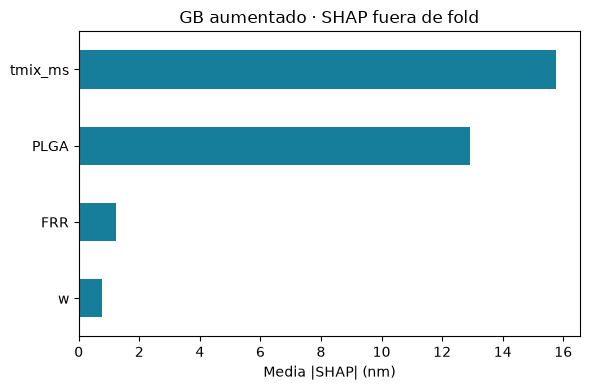

In [5]:
# ============================================================
# Algoritmo SHAP exacto por enumeración de coaliciones
# ------------------------------------------------------------
# Esencia: Implementación desde primeros principios de los valores de
# Shapley intervencionales para d = 4 variables (FRR, PLGA, w, tmix_ms),
# evaluando exhaustivamente las 2^d = 16 combinaciones de coaliciones S.
#   - background: Conjunto de datos de referencia (entrenamiento del fold).
#   - baseline: Predicción promedio del modelo sobre el fondo, E[f(X)].
#   - Ponderación: Factor combinatorio |S|!(d - |S| - 1)! / d!.
#   - Aserción de eficiencia: Verifica la propiedad fundamental de aditividad:
#     sum_j(phi_j) + baseline == f(x) con tolerancia numérica estricta (1e-8).
# ============================================================
def shap_exact(model, background, test):
    b = background.to_numpy()
    d = b.shape[1]
    out = []
    baseline = model.predict(background).mean()
    
    for x in test.to_numpy():
        vals = {}
        # Evaluación de todas las coaliciones posibles de tamaño k = 0, ..., d
        for k in range(d + 1):
            for S in itertools.combinations(range(d), k):
                z = b.copy()
                if S:
                    z[:, list(S)] = x[list(S)]
                vals[frozenset(S)] = model.predict(pd.DataFrame(z, columns=background.columns)).mean()
        
        # Ponderación combinatoria para cada característica j
        phi = np.zeros(d)
        for j in range(d):
            others = set(range(d)) - {j}
            for k in range(d):
                for S in itertools.combinations(sorted(others), k):
                    s = frozenset(S)
                    peso = math.factorial(k) * math.factorial(d - k - 1) / math.factorial(d)
                    phi[j] += peso * (vals[s | {j}] - vals[s])
        out.append(phi)
        
    out = np.array(out)
    # Verificación de la propiedad de eficiencia / aditividad local
    assert np.allclose(out.sum(1) + baseline, model.predict(test), atol=1e-8)
    return out


# ============================================================
# Cálculo de SHAP fuera de pliegue (OOF) y ranking de importancia
# ------------------------------------------------------------
# Esencia: Ejecuta shap_exact fold por fold para el modelo Gradient
# Boosting con espacio Aumentado, utilizando en cada caso el split de
# entrenamiento como fondo y calculando los valores sobre las muestras OOF.
# Garantiza explicabilidad sin fuga de datos entre réplicas.
# Computa la importancia global como la media del valor absoluto (mean |SHAP|),
# exporta matrices y genera el gráfico de barras horizontales en shap_summary.pdf.
# ============================================================
cols = features['Aumentado']
sh = np.zeros((len(df), len(cols)))

# Cálculo OOF para cada partición de GroupKFold
for a, b in group_folds:
    m = modelos()['GB'].fit(df[cols].iloc[a], y[a])
    sh[b] = shap_exact(m, df[cols].iloc[a], df[cols].iloc[b])

# Importancia global: magnitud promedio del impacto en el diámetro (nm)
importance = pd.Series(np.abs(sh).mean(0), index=cols).sort_values()
print(importance)

# Persistencia de artefactos CSV
importance.to_csv(OUT / 'shap_importancia.csv')
pd.DataFrame(sh, columns=cols).to_csv(OUT / 'shap_oof.csv', index=False)

# Visualización del perfil de importancia de características
fig, ax = plt.subplots(figsize=(6, 4))
importance.plot.barh(ax=ax, color='#167D9A')
ax.set(xlabel='Media |SHAP| (nm)', title='GB aumentado · SHAP fuera de fold')
fig.tight_layout()
fig.savefig(OUT / 'shap_summary.pdf')
plt.show()


## Discusión
La comparación agrupada evita que una réplica de la misma configuración aparezca en entrenamiento y prueba. Una caída de rendimiento respecto al hold-out no contradice el paper: cambia la pregunta de validación. Un RMSE menor del modelo físico indicaría utilidad predictiva de la parametrización, no causalidad; un RMSE mayor indicaría pérdida de información o limitaciones del regresor. El bootstrap no incorpora toda la incertidumbre del entrenamiento. D es fijo, por lo que cambiarlo por otro valor constante solo reescala el descriptor. La extrapolación fuera del dominio experimental no está garantizada. No se usan datos sintéticos ni deep learning.

In [6]:
# ============================================================
# Síntesis de resultados para Gradient Boosting y test de hipótesis
# ------------------------------------------------------------
# Esencia: Consolida el desempeño out-of-fold de Gradient Boosting
# a través de las 4 hipótesis de características bajo validación
# agrupada (GroupKFold). Dictamina cuantitativamente si la inclusión
# del descriptor físico tmix mejora el error de generalización respecto
# al modelo base, complementándolo con el intervalo bootstrap al 95%.
# Exporta los tensores delta e IC a 'resultados/bootstrap.npz'.
# ============================================================
print('GB agrupado:')
print(gap.query('modelo==GB').round(4).to_string(index=False))

# Dictamen de la hipótesis física condicional al modelo empírico ajustado
print('El desempeño físico', 'mejora' if delta < 0 else 'no mejora',
      'el RMSE OOF del GB base; IC descriptivo', ci)

# Almacenamiento binario persistente de los estadísticos bootstrap
np.savez(OUT / 'bootstrap.npz', delta=delta, ci=ci)


GB agrupado:
modelo  variables     R2   RMSE    MAE  RMSE_fold
    GB       Base 0.9039 8.1507 6.7748     8.1054
    GB  Aumentado 0.9069 8.0229 6.2979     7.3632
    GB     Fisico 0.9098 7.8957 6.7247     7.4980
    GB Fisico_log 0.9098 7.8957 6.7247     7.4980
El desempeño físico mejora el RMSE OOF del GB base; IC descriptivo [-2.23646182  1.58583003]
